# Trabalho Integrado de Fundamentos de IA — Etapa 6
## Lógica Fuzzy (Mamdani) e Integração Final do Pipeline de IA

**Equipe 2:** Domínio da Saúde Pública — Vigilância Epidemiológica e Vacinação PNI  
**Base de Dados:** Microdados Oficiais do PNI (2023–2026) — API de Dados Abertos do Ministério da Saúde  

---

### 1. Objetivos da Etapa 6
Nesta etapa conclusiva, integramos todo o conhecimento adquirido nas etapas anteriores através de um **Sistema de Inferência Fuzzy Mamdani**:
1. **Variáveis Linguísticas:** Mapeamos variáveis contínuas em termos qualitativos humanamente interpretáveis (`risco_bayesiano`, `vulnerabilidade_populacional` e `urgencia_auditoria`).
2. **Funções de Pertinência:** Modelagem de conjuntos fuzzy triangulares (`trimf`).
3. **Base de Regras Especialistas:** Conjunto de regras Se-Então com operadores de conjunção e disjunção orientadas à tomada de decisão no SUS.
4. **Integração Ponta a Ponta:** Alimentação direta com as probabilidades a posteriori calculadas pela **Rede Bayesiana da Etapa 5**.
5. **Contraste Suave vs. Rígido:** Comparação da superfície de decisão fuzzy contra thresholds booleanos arbitrários (0.5).
6. **Superfície de Controle 3D:** Plotagem da transição suave da prioridade de intervenção.
7. **Visão Holística:** Apresentação do diagrama completo do pipeline de IA integrado em 6 etapas.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

sys.path.append(os.path.abspath('..'))
from src.utils import load_and_preprocess_pni
from src.bayesian_net import BayesianNetworkScratch
from src.fuzzy_system import HealthFuzzyInferenceSystem

import skfuzzy as fuzz

np.random.seed(42)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

### 2. Tarefa 1 e 2 — Definição das Variáveis Linguísticas e Funções de Pertinência

Para modelar a priorização de auditoria e suporte técnico às salas de vacina, definimos:
1. **Antecedente 1: `Risco_Bayesiano` $\in [0.0, 1.0]$**  
   Probabilidade a posteriori de atraso crítico $P(A=1 \mid e)$ vinda da Rede Bayesiana.  
   - Baixo: $\text{trimf}([0.0, 0.0, 0.4])$  
   - Médio: $\text{trimf}([0.2, 0.5, 0.8])$  
   - Alto: $\text{trimf}([0.6, 1.0, 1.0])$  
2. **Antecedente 2: `Vulnerabilidade_Populacional` $\in [0, 100]$**  
   Percentual de crianças menores de 4 anos e idosos atendidos na unidade.  
   - Baixa: $\text{trimf}([0, 0, 40])$  
   - Média: $\text{trimf}([20, 50, 80])$  
   - Alta: $\text{trimf}([60, 100, 100])$  
3. **Consequente: `Urgencia_Intervencao` $\in [0, 100]$**  
   Escore contínuo de prioridade de apoio operacional e infraestrutura pelo Ministério da Saúde.  
   - Baixa: $\text{trimf}([0, 0, 40])$  
   - Média: $\text{trimf}([25, 50, 75])$  
   - Crítica / Alta: $\text{trimf}([60, 100, 100])$

<>:12: SyntaxWarning: invalid escape sequence '\m'
<>:21: SyntaxWarning: invalid escape sequence '\m'
<>:30: SyntaxWarning: invalid escape sequence '\m'
<>:12: SyntaxWarning: invalid escape sequence '\m'
<>:21: SyntaxWarning: invalid escape sequence '\m'
<>:30: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_830406/2058817564.py:12: SyntaxWarning: invalid escape sequence '\m'
  axes[0].set_ylabel('Grau de Pertinência $\mu$')
/tmp/ipykernel_830406/2058817564.py:21: SyntaxWarning: invalid escape sequence '\m'
  axes[1].set_ylabel('Grau de Pertinência $\mu$')
/tmp/ipykernel_830406/2058817564.py:30: SyntaxWarning: invalid escape sequence '\m'
  axes[2].set_ylabel('Grau de Pertinência $\mu$')


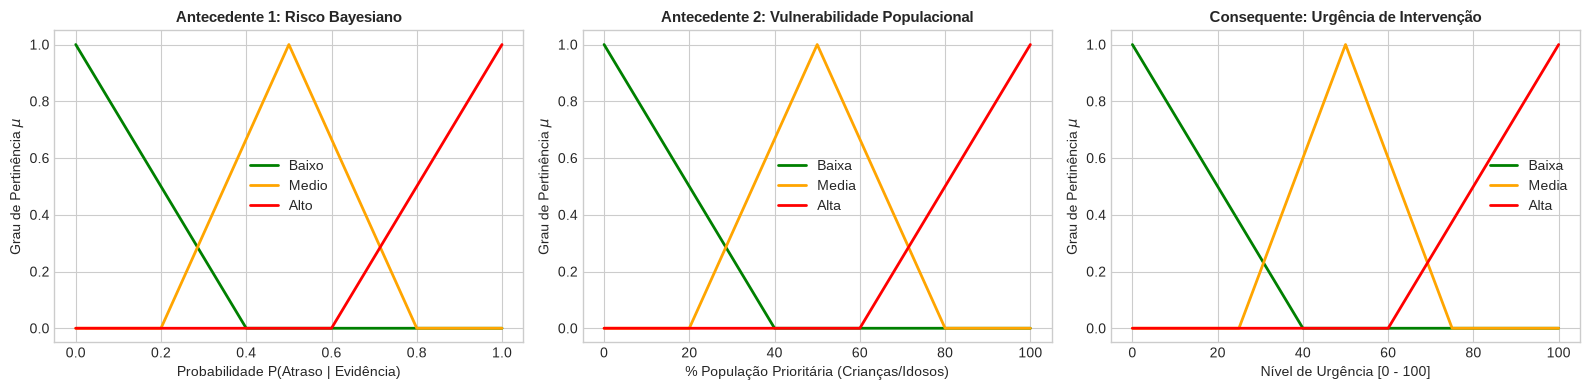

In [2]:
fuzzy_sys = HealthFuzzyInferenceSystem()

# Visualização das Funções de Pertinência
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Risco Bayesiano
u_risco = fuzzy_sys.risco.universe
for label, color in [('baixo', 'green'), ('medio', 'orange'), ('alto', 'red')]:
    axes[0].plot(u_risco, fuzzy_sys.risco[label].mf, label=label.capitalize(), color=color, linewidth=2)
axes[0].set_title('Antecedente 1: Risco Bayesiano', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Probabilidade P(Atraso | Evidência)')
axes[0].set_ylabel('Grau de Pertinência $\mu$')
axes[0].legend()

# Vulnerabilidade Populacional
u_vuln = fuzzy_sys.vulnerabilidade.universe
for label, color in [('baixa', 'green'), ('media', 'orange'), ('alta', 'red')]:
    axes[1].plot(u_vuln, fuzzy_sys.vulnerabilidade[label].mf, label=label.capitalize(), color=color, linewidth=2)
axes[1].set_title('Antecedente 2: Vulnerabilidade Populacional', fontsize=11, fontweight='bold')
axes[1].set_xlabel('% População Prioritária (Crianças/Idosos)')
axes[1].set_ylabel('Grau de Pertinência $\mu$')
axes[1].legend()

# Urgência de Auditoria
u_urg = fuzzy_sys.urgencia.universe
for label, color in [('baixa', 'green'), ('media', 'orange'), ('alta', 'red')]:
    axes[2].plot(u_urg, fuzzy_sys.urgencia[label].mf, label=label.capitalize(), color=color, linewidth=2)
axes[2].set_title('Consequente: Urgência de Intervenção', fontsize=11, fontweight='bold')
axes[2].set_xlabel('Nível de Urgência [0 - 100]')
axes[2].set_ylabel('Grau de Pertinência $\mu$')
axes[2].legend()

plt.tight_layout()
plt.show()

### 3. Tarefa 3 — Base de Regras Se-Então (Sistema Mamdani)

As regras especialistas foram elaboradas para refletir as prioridades de vigilância em saúde:
1. **R1:** SE *Risco* é **Alto** E *Vulnerabilidade* é **Alta**, ENTÃO *Urgência* é **Alta**  
   *(Cenário Crítico: Unidade sob forte risco de apagão de dados atendendo público infantil/idoso).*  
2. **R2:** SE *Risco* é **Alto** E *Vulnerabilidade* NÃO é **Alta**, ENTÃO *Urgência* é **Média**  
   *(Atraso provável, porém a população atendida tem menor risco imediato de surtos severos).*  
3. **R3:** SE *Risco* é **Médio**, ENTÃO *Urgência* é **Média**  
   *(Zona de transição que requer monitoramento preventivo).*  
4. **R4:** SE *Risco* é **Baixo** E *Vulnerabilidade* NÃO é **Alta**, ENTÃO *Urgência* é **Baixa**  
   *(Unidade operando dentro dos padrões satisfatórios de transmissão).*  
5. **R5:** SE *Risco* é **Baixo** E *Vulnerabilidade* é **Alta**, ENTÃO *Urgência* é **Média**  
   *(Prevenção por cautela: apesar do baixo risco, o impacto sanitário de uma falha seria intolerável).*

### 4. Tarefa 5 — Integração com as Probabilidades da Rede Bayesiana (Etapa 5)

Demonstramos a integração alimentando o motor fuzzy com as probabilidades condicionais inferidas na Rede Bayesiana da Etapa 5 sob diferentes perfis de unidades de saúde.

In [3]:
# Carregar e ajustar a Rede Bayesiana da Etapa 5
df = load_and_preprocess_pni('../data/vacinacao_pni_amostra.parquet')
df_bn = pd.DataFrame()
df_bn['R'] = df['regiao'].apply(lambda r: 1 if r in ['Norte', 'Nordeste'] else 0)
df_bn['S'] = df['sistema_offline'].astype(int)
df_bn['V'] = df['faixa_etaria'].apply(lambda f: 1 if f in ['Crianca', 'Idoso'] else 0)
df_bn['N'] = df['fabricante'].apply(lambda f: 1 if f in ['Butantan', 'Fiocruz'] else 0)
df_bn['A'] = df['atraso_critico'].astype(int)

bn = BayesianNetworkScratch().fit(df_bn)

# Cenários de Teste Integrados:
cenarios = [
    {
        'nome': 'Posto Rural Remoto (N/NE, Offline, Vacina Nacional)',
        'evidence': {'R': 1, 'S': 1, 'N': 1},
        'vulnerabilidade': 85.0
    },
    {
        'nome': 'Unidade Urbana Central (Sul/SE, Online, Multinacional)',
        'evidence': {'R': 0, 'S': 0, 'N': 0},
        'vulnerabilidade': 30.0
    },
    {
        'nome': 'Unidade de Fronteira / Vulnerabilidade Intermediária',
        'evidence': {'R': 1, 'S': 0, 'N': 1},
        'vulnerabilidade': 65.0
    }
]

print("=== INTEGRAÇÃO: REDE BAYESIANA (ETAPA 5) -> SISTEMA FUZZY (ETAPA 6) ===\n")
for c in cenarios:
    # 1. Inferência Bayesiana da probabilidade de atraso crítico
    post = bn.query_by_enumeration('A', c['evidence'])
    p_atraso = post[1]
    
    # 2. Defuzzificação Mamdani por Centro de Gravidade
    urgencia_saida = fuzzy_sys.evaluate(p_atraso, c['vulnerabilidade'])
    
    print(f"Cenário: {c['nome']}")
    print(f"  Evidências              : {c['evidence']}")
    print(f"  P(Atraso Crítico | Evid): {p_atraso:.4f} ({p_atraso*100:.2f}%)")
    print(f"  Vulnerabilidade Inserida: {c['vulnerabilidade']:.1f}%")
    print(f"  --> Urgência Fuzzy Final: {urgencia_saida:.2f} / 100\n")

[Data Loader] 16000 registros brutos carregados.
[Data Loader] 15403 registros válidos após higienização.
[Distribuição Alvo] Atraso Crítico (>7 dias): 51.6% positivo.
=== INTEGRAÇÃO: REDE BAYESIANA (ETAPA 5) -> SISTEMA FUZZY (ETAPA 6) ===

Cenário: Posto Rural Remoto (N/NE, Offline, Vacina Nacional)
  Evidências              : {'R': 1, 'S': 1, 'N': 1}
  P(Atraso Crítico | Evid): 0.7458 (74.58%)
  Vulnerabilidade Inserida: 85.0%
  --> Urgência Fuzzy Final: 64.61 / 100

Cenário: Unidade Urbana Central (Sul/SE, Online, Multinacional)
  Evidências              : {'R': 0, 'S': 0, 'N': 0}
  P(Atraso Crítico | Evid): 0.3059 (30.59%)
  Vulnerabilidade Inserida: 30.0%
  --> Urgência Fuzzy Final: 38.79 / 100

Cenário: Unidade de Fronteira / Vulnerabilidade Intermediária
  Evidências              : {'R': 1, 'S': 0, 'N': 1}
  P(Atraso Crítico | Evid): 0.1758 (17.58%)
  Vulnerabilidade Inserida: 65.0%
  --> Urgência Fuzzy Final: 23.90 / 100



### 5. Tarefa 6 — Decisão Suave Fuzzy vs. Limiar Booleano Rígido ("Hard Threshold")

Um sistema booleano tradicional adota um corte arbitrário (ex.: $P > 0.5 \implies \text{Intervenção Máxima}$; $P \le 0.5 \implies \text{Sem Intervenção}$).
Isso gera o fenômeno patológico da **descontinuidade de fronteira**: uma pequena alteração nos dados (de $0.499$ para $0.501$) provoca um salto abrupto e desestabilizador nas decisões administrativas.

Abaixo contrastamos a resposta contínua e suave do sistema fuzzy com o degrau de um corte rígido.

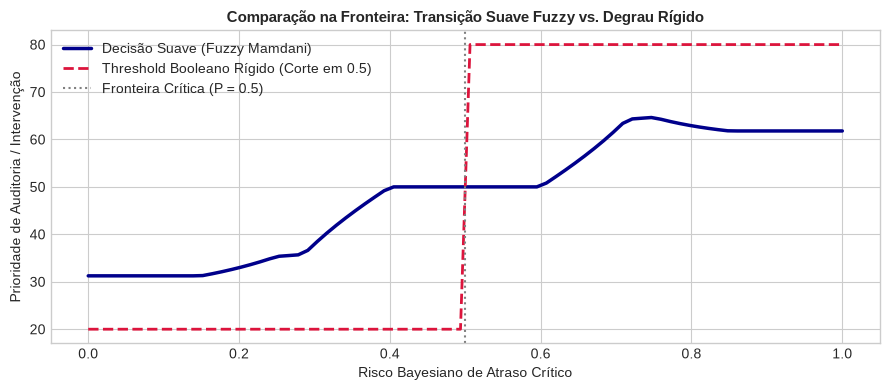

In [4]:
# Variação contínua do risco bayesiano de 0.0 a 1.0 com vulnerabilidade constante = 75%
riscos_grid = np.linspace(0.0, 1.0, 80)
decisoes_fuzzy = [fuzzy_sys.evaluate(r, 75.0) for r in riscos_grid]
decisoes_hard = [80.0 if r > 0.5 else 20.0 for r in riscos_grid]

plt.figure(figsize=(9, 4))
plt.plot(riscos_grid, decisoes_fuzzy, color='darkblue', linewidth=2.5, label='Decisão Suave (Fuzzy Mamdani)')
plt.plot(riscos_grid, decisoes_hard, color='crimson', linestyle='--', linewidth=2, label='Threshold Booleano Rígido (Corte em 0.5)')
plt.axvline(0.5, color='gray', linestyle=':', label='Fronteira Crítica (P = 0.5)')
plt.title('Comparação na Fronteira: Transição Suave Fuzzy vs. Degrau Rígido', fontsize=11, fontweight='bold')
plt.xlabel('Risco Bayesiano de Atraso Crítico')
plt.ylabel('Prioridade de Auditoria / Intervenção')
plt.legend()
plt.tight_layout()
plt.show()

### 6. Superfície de Controle 3D do Sistema Fuzzy
A superfície de controle tridimensional mapeia todo o espaço de estados contínuo de entrada no escore de decisão final.

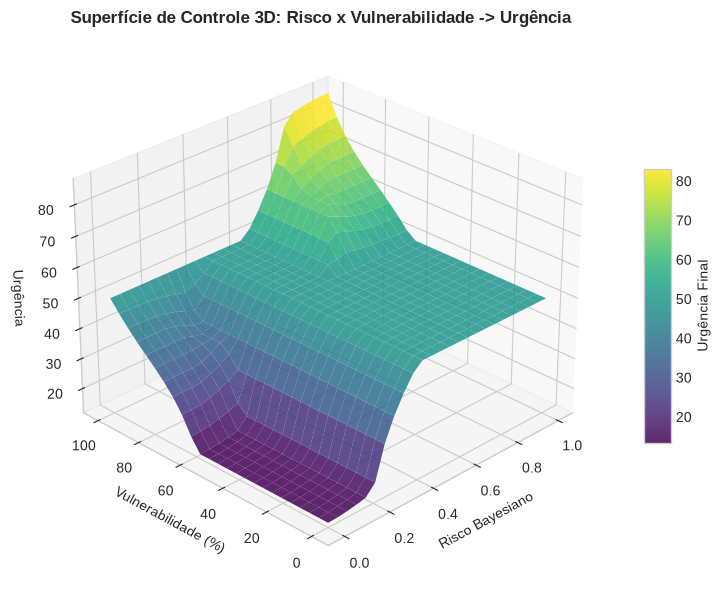

In [5]:
X_surf, Y_surf, Z_surf = fuzzy_sys.compute_control_surface(resolution=25)

fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111, projection='3d')
surf = ax.plot_surface(X_surf, Y_surf, Z_surf, cmap='viridis', edgecolor='none', alpha=0.85)

ax.set_title('Superfície de Controle 3D: Risco x Vulnerabilidade -> Urgência', fontsize=12, fontweight='bold')
ax.set_xlabel('Risco Bayesiano')
ax.set_ylabel('Vulnerabilidade (%)')
ax.set_zlabel('Urgência')
fig.colorbar(surf, ax=ax, shrink=0.5, aspect=10, label='Urgência Final')
ax.view_init(elev=28, azim=225)
plt.tight_layout()
plt.show()

### 7. Seção 10 da Especificação — Integração Final: O Pipeline Completo

O diagrama abaixo resume a arquitetura de dados e aprendizado construída ao longo das 6 etapas:

```
                                   Dados Oficiais (PNI / MS)
                                                │
                                                ▼
                                 Etapa 1: Árvore de Decisão
                                 (Seleção Simbólica de Atributos)
                                                │
                                                ▼
                                Etapa 2: Regressão + Logística
                                (Modelos Paramétricos & OLS/GD)
                                                │
                                                ▼
                                    Etapa 3: Probabilidade
                                 (Distribuição Conjunta & Bayes)
                                                │
                                                ▼
                                Etapa 4: Naive Bayes + EM
                                (Parâmetros MLE/MAP & Latente Z)
                                                │
                                                ▼
                                  Etapa 5: Rede Bayesiana
                                 (DAG, CPTs, Inferência & d-sep)
                                                │
                                                ▼ (Probabilidades Bayesianas)
                                   Etapa 6: Sistema Fuzzy
                                 (Mamdani, Regras & Pertinências)
                                                │
                                                ▼
                                  Decisão Final Interpretável
                            (Escore Suave de Intervenção SUS)
```

### 8. Discussão sobre Interpretabilidade e Conclusão
1. **Auditabilidade Total:** Ao contrário de redes neurais opacas ("caixas-pretas"), cada decisão do sistema fuzzy pode ser rastreada até a regra linguística ativada e até a CPT da Rede Bayesiana.
2. **Resiliência a Ruído:** Em dados de saúde pública com frequentes imprecisões de digitação e registros tardios, o sistema fuzzy evita polarizações artificiais e prioriza os recursos públicos de maneira gradual e justificada.
3. **Alinhamento com o Especialista:** A tomada de decisão reproduz fielmente as heurísticas e o bom senso de gestores de vigilância em saúde.